In [1]:
# ==========================================
# 01. ENVIRONMENT SETUP
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Project directory
PROJECT_DIR = Path.cwd().parent

# Data and result directories
DATA_DIR = PROJECT_DIR / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "models"
RESULT_DIR = PROJECT_DIR / "results"
FORECAST_DIR = RESULT_DIR / "forecasts"

print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Model directory:", MODEL_DIR)

Project directory: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week12-Time Series Analysis\FS\Time_Series_AI
Data directory: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week12-Time Series Analysis\FS\Time_Series_AI\data\processed
Model directory: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week12-Time Series Analysis\FS\Time_Series_AI\models


In [2]:
# ==========================================
# 02. LOAD PROCESSED DATA
# ==========================================

target = pd.read_pickle(
    DATA_DIR / "target_original.pkl"
)["electricity"]

target_interpolated = pd.read_pickle(
    DATA_DIR / "target_interpolated.pkl"
)["electricity"]

train = pd.read_pickle(
    DATA_DIR / "train.pkl"
)["electricity"]

test = pd.read_pickle(
    DATA_DIR / "test.pkl"
)["electricity"]

print("Dataset loaded successfully!")

print("\nOriginal target:", target.shape)
print("Interpolated target:", target_interpolated.shape)
print("Training data:", train.shape)
print("Testing data:", test.shape)

print("\nTraining period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Dataset loaded successfully!

Original target: (14166,)
Interpolated target: (14166,)
Training data: (11332,)
Testing data: (2834,)

Training period: 2016-05-20 18:00:00 to 2017-09-04 21:00:00
Testing period: 2017-09-04 22:00:00 to 2017-12-31 23:00:00


In [3]:
# ==========================================
# 03. CREATE LAG FEATURES
# ==========================================

ml_data = pd.DataFrame(index=target_interpolated.index)

ml_data["target"] = target_interpolated

for lag in [1, 2, 3, 24, 48]:
    ml_data[f"lag_{lag}"] = target_interpolated.shift(lag)

# Remove rows without sufficient historical observations
ml_data = ml_data.dropna()

print("ML dataset shape:", ml_data.shape)

display(ml_data.head(10))

ML dataset shape: (14118, 6)


,target,lag_1,lag_2,lag_3,lag_24,lag_48
timestamp,,,,,,
2016-05-22 18:00:00,28.2054,29.5257,27.8454,27.4853,22.2043,26.1651
2016-05-22 19:00:00,28.0854,28.2054,29.5257,27.8454,21.2441,35.4068
2016-05-22 20:00:00,26.1651,28.0854,28.2054,29.5257,21.3641,38.5274
2016-05-22 21:00:00,26.7652,26.1651,28.0854,28.2054,22.4443,23.6446
2016-05-22 22:00:00,25.0848,26.7652,26.1651,28.0854,21.9642,18.6036
2016-05-22 23:00:00,25.4449,25.0848,26.7652,26.1651,21.4842,18.3635
2016-05-23 00:00:00,23.6446,25.4449,25.0848,26.7652,20.4039,18.2435
2016-05-23 01:00:00,23.2845,23.6446,25.4449,25.0848,19.0837,18.3635
2016-05-23 02:00:00,46.4490,23.2845,23.6446,25.4449,18.9637,18.2435


In [4]:
# ==========================================
# 04. CHRONOLOGICAL TRAIN / TEST SPLIT
# ==========================================

# Separate input features and prediction target
X = ml_data.drop(columns=["target"])
y = ml_data["target"]

# Preserve the original training and testing periods
X_train = X.loc[train.index.intersection(X.index)]
X_test = X.loc[test.index.intersection(X.index)]

y_train = y.loc[X_train.index]
y_test = y.loc[X_test.index]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining period:", X_train.index.min(), "to", X_train.index.max())
print("Testing period:", X_test.index.min(), "to", X_test.index.max())

Training features: (11284, 5)
Testing features: (2834, 5)

Training period: 2016-05-22 18:00:00 to 2017-09-04 21:00:00
Testing period: 2017-09-04 22:00:00 to 2017-12-31 23:00:00


In [5]:
# ==========================================
# 05. RANDOM FOREST REGRESSION
# ==========================================

from sklearn.ensemble import RandomForestRegressor

# Initialise model
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")
print("Number of trees:", rf_model.n_estimators)
print("Training observations:", len(X_train))
print("Features:", list(X_train.columns))

Random Forest training completed!
Number of trees: 300
Training observations: 11284
Features: ['lag_1', 'lag_2', 'lag_3', 'lag_24', 'lag_48']


In [6]:
# ==========================================
# 06. RANDOM FOREST PREDICTIONS
# ==========================================

rf_predictions = rf_model.predict(X_test)

rf_predictions = pd.Series(
    rf_predictions,
    index=X_test.index,
    name="Random_Forest"
)

print("Predictions generated:", len(rf_predictions))

display(pd.DataFrame({
    "Actual": y_test.head(10),
    "Predicted": rf_predictions.head(10)
}))

Predictions generated: 2834


,Actual,Predicted
timestamp,,
2017-09-04 22:00:00,21.9642,23.492524
2017-09-04 23:00:00,21.9642,22.277887
2017-09-05 00:00:00,22.8044,21.720974
2017-09-05 01:00:00,20.8840,22.752663
2017-09-05 02:00:00,21.0040,21.339321
2017-09-05 03:00:00,20.6440,21.925443
2017-09-05 04:00:00,20.5240,21.941046
2017-09-05 05:00:00,21.0040,20.585976
2017-09-05 06:00:00,43.9285,22.394728


In [7]:
# ==========================================
# 07. RANDOM FOREST EVALUATION
# ==========================================

from sklearn.metrics import mean_absolute_error, mean_squared_error

rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

print(f"Random Forest MAE:  {rf_mae:.3f}")
print(f"Random Forest RMSE: {rf_rmse:.3f}")

Random Forest MAE:  2.797
Random Forest RMSE: 4.976


In [8]:
# ==========================================
# 08. TIME-BASED FEATURE ENGINEERING
# ==========================================

ml_data_advanced = ml_data.copy()

# Time features
ml_data_advanced["hour"] = ml_data_advanced.index.hour

ml_data_advanced["day_of_week"] = (
    ml_data_advanced.index.dayofweek
)

ml_data_advanced["is_weekend"] = (
    ml_data_advanced["day_of_week"] >= 5
).astype(int)

# Rolling features: shift first to avoid using the current target
ml_data_advanced["rolling_mean_3"] = (
    target_interpolated.shift(1).rolling(3).mean()
)

ml_data_advanced["rolling_mean_24"] = (
    target_interpolated.shift(1).rolling(24).mean()
)

# Remove rows with missing feature values
ml_data_advanced = ml_data_advanced.dropna()

print("Advanced dataset shape:", ml_data_advanced.shape)

display(ml_data_advanced.head(10))

Advanced dataset shape: (14118, 11)


,target,lag_1,lag_2,lag_3,lag_24,lag_48,hour,day_of_week,is_weekend,rolling_mean_3,rolling_mean_24
timestamp,,,,,,,,,,,
2016-05-22 18:00:00,28.2054,29.5257,27.8454,27.4853,22.2043,26.1651,18,6,1,28.285467,21.749200
2016-05-22 19:00:00,28.0854,28.2054,29.5257,27.8454,21.2441,35.4068,19,6,1,28.525500,21.999246
2016-05-22 20:00:00,26.1651,28.0854,28.2054,29.5257,21.3641,38.5274,20,6,1,28.605500,22.284300
2016-05-22 21:00:00,26.7652,26.1651,28.0854,28.2054,22.4443,23.6446,21,6,1,27.485300,22.484342
2016-05-22 22:00:00,25.0848,26.7652,26.1651,28.0854,21.9642,18.6036,22,6,1,27.005233,22.664379
2016-05-22 23:00:00,25.4449,25.0848,26.7652,26.1651,21.4842,18.3635,23,6,1,26.005033,22.794404
2016-05-23 00:00:00,23.6446,25.4449,25.0848,26.7652,20.4039,18.2435,0,0,0,25.764967,22.959433
2016-05-23 01:00:00,23.2845,23.6446,25.4449,25.0848,19.0837,18.3635,1,0,0,24.724767,23.094462
2016-05-23 02:00:00,46.4490,23.2845,23.6446,25.4449,18.9637,18.2435,2,0,0,24.124667,23.269496


In [9]:
# ==========================================
# 09. ADVANCED TRAIN / TEST SPLIT
# ==========================================

X_advanced = ml_data_advanced.drop(columns=["target"])
y_advanced = ml_data_advanced["target"]

X_train_advanced = X_advanced.loc[
    train.index.intersection(X_advanced.index)
]

X_test_advanced = X_advanced.loc[
    test.index.intersection(X_advanced.index)
]

y_train_advanced = y_advanced.loc[X_train_advanced.index]
y_test_advanced = y_advanced.loc[X_test_advanced.index]

print("Training features:", X_train_advanced.shape)
print("Testing features:", X_test_advanced.shape)

print("\nFeatures:", list(X_train_advanced.columns))

print("\nTraining period:",
      X_train_advanced.index.min(),
      "to",
      X_train_advanced.index.max())

print("Testing period:",
      X_test_advanced.index.min(),
      "to",
      X_test_advanced.index.max())

Training features: (11284, 10)
Testing features: (2834, 10)

Features: ['lag_1', 'lag_2', 'lag_3', 'lag_24', 'lag_48', 'hour', 'day_of_week', 'is_weekend', 'rolling_mean_3', 'rolling_mean_24']

Training period: 2016-05-22 18:00:00 to 2017-09-04 21:00:00
Testing period: 2017-09-04 22:00:00 to 2017-12-31 23:00:00


In [10]:
rf_advanced_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

rf_advanced_model.fit(X_train_advanced, y_train_advanced)

print("Advanced Random Forest training completed.")
print("Trees:", rf_advanced_model.n_estimators)
print("Training observations:", len(X_train_advanced))
print("Number of features:", X_train_advanced.shape[1])

Advanced Random Forest training completed.
Trees: 300
Training observations: 11284
Number of features: 10


In [11]:
rf_advanced_predictions = pd.Series(
    rf_advanced_model.predict(X_test_advanced),
    index=X_test_advanced.index,
    name="Random_Forest_Advanced"
)

print("Predictions generated:", len(rf_advanced_predictions))

comparison_preview = pd.DataFrame({
    "Actual": y_test_advanced,
    "Baseline_RF": rf_predictions,
    "Advanced_RF": rf_advanced_predictions
})

display(comparison_preview.head(10))

Predictions generated: 2834


,Actual,Baseline_RF,Advanced_RF
timestamp,,,
2017-09-04 22:00:00,21.9642,23.492524,23.916669
2017-09-04 23:00:00,21.9642,22.277887,24.810156
2017-09-05 00:00:00,22.8044,21.720974,23.182455
2017-09-05 01:00:00,20.8840,22.752663,24.190653
2017-09-05 02:00:00,21.0040,21.339321,21.417732
2017-09-05 03:00:00,20.6440,21.925443,22.185489
2017-09-05 04:00:00,20.5240,21.941046,26.186658
2017-09-05 05:00:00,21.0040,20.585976,28.329070
2017-09-05 06:00:00,43.9285,22.394728,35.893736


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

def evaluate_forecast(actual, predicted, original_target):

    # Identify timestamps with original, non-missing readings
    valid_mask = original_target.loc[actual.index].notna()

    actual_valid = actual[valid_mask]
    predicted_valid = predicted[valid_mask]

    # Calculate evaluation metrics
    mae = mean_absolute_error(actual_valid, predicted_valid)
    rmse = np.sqrt(mean_squared_error(actual_valid, predicted_valid))

    return mae, rmse

In [14]:
baseline_mae, baseline_rmse = evaluate_forecast(
    y_test, rf_predictions, target
)

advanced_mae, advanced_rmse = evaluate_forecast(
    y_test_advanced, rf_advanced_predictions, target
)

rf_comparison = pd.DataFrame([
    {
        "Model": "Baseline Random Forest",
        "MAE": baseline_mae,
        "RMSE": baseline_rmse
    },
    {
        "Model": "Advanced Random Forest",
        "MAE": advanced_mae,
        "RMSE": advanced_rmse
    }
])

display(rf_comparison.round(3))

,Model,MAE,RMSE
0,Baseline Random Forest,2.797,4.976
1,Advanced Random Forest,2.200,4.123


In [15]:
feature_importance = pd.DataFrame({
    "Feature": X_train_advanced.columns,
    "Importance": rf_advanced_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.round(4))

,Feature,Importance
0,lag_1,0.9215
5,hour,0.0260
3,lag_24,0.0224
9,rolling_mean_24,0.0077
1,lag_2,0.0045
4,lag_48,0.0045
2,lag_3,0.0041
6,day_of_week,0.0039
8,rolling_mean_3,0.0038
7,is_weekend,0.0016


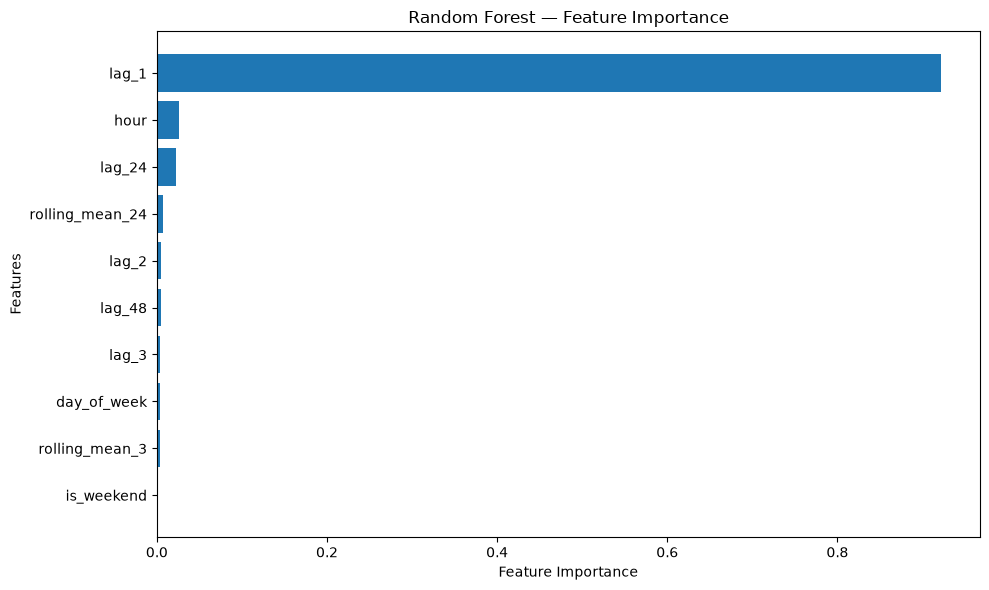

In [16]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest — Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [18]:
statistical_forecasts = pd.read_csv(
    FORECAST_DIR / "statistical_forecasts.csv",
    index_col=0,
    parse_dates=True
)

print("Available forecast columns:")
print(statistical_forecasts.columns.tolist())

print("\nShape:", statistical_forecasts.shape)
display(statistical_forecasts.head())

Available forecast columns:
['actual', 'naive', 'seasonal_naive', 'holt_winters', 'arima']

Shape: (2834, 5)


,actual,naive,seasonal_naive,holt_winters,arima
timestamp,,,,,
2017-09-04 22:00:00,21.9642,22.8044,21.0040,19.785942,23.526014
2017-09-04 23:00:00,21.9642,21.9642,19.9238,23.039854,22.503253
2017-09-05 00:00:00,22.8044,21.9642,20.2839,23.304500,22.702759
2017-09-05 01:00:00,20.8840,22.8044,19.3237,23.293341,23.619793
2017-09-05 02:00:00,21.0040,20.8840,19.8038,21.039456,21.255945


In [20]:
# Reconnect saved statistical forecasts
hw_predictions = statistical_forecasts["holt_winters"]
arima_predictions = statistical_forecasts["arima"]

# Build comparison dynamically
all_results = []

def add_result(name, actual, predicted, original_target, evaluation):
    mae, rmse = evaluate_forecast(actual, predicted, original_target)

    all_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "Evaluation": evaluation
    })

# Full-test comparison
add_result("Naive", y_test, statistical_forecasts["naive"], target, "Full test")
add_result("Holt-Winters", y_test, hw_predictions, target, "Full test")
add_result("ARIMA", y_test, arima_predictions, target, "Full test")
add_result("Baseline Random Forest", y_test, rf_predictions, target, "Full test")
add_result("Advanced Random Forest", y_test_advanced, rf_advanced_predictions, target, "Full test")

final_comparison = pd.DataFrame(all_results)

display(
    final_comparison.sort_values("MAE").round(3)
)

,Model,MAE,RMSE,Evaluation
4,Advanced Random Forest,2.200,4.123,Full test
1,Holt-Winters,2.461,4.377,Full test
0,Naive,2.553,5.523,Full test
2,ARIMA,2.657,5.224,Full test
3,Baseline Random Forest,2.797,4.976,Full test


The Advanced Random Forest achieved the lowest forecasting error among the models evaluated over the full test period. Incorporating temporal and rolling statistical features improved the baseline Random Forest's MAE by approximately 21.3%. The results indicate that feature engineering can improve short-term building electricity forecasting.

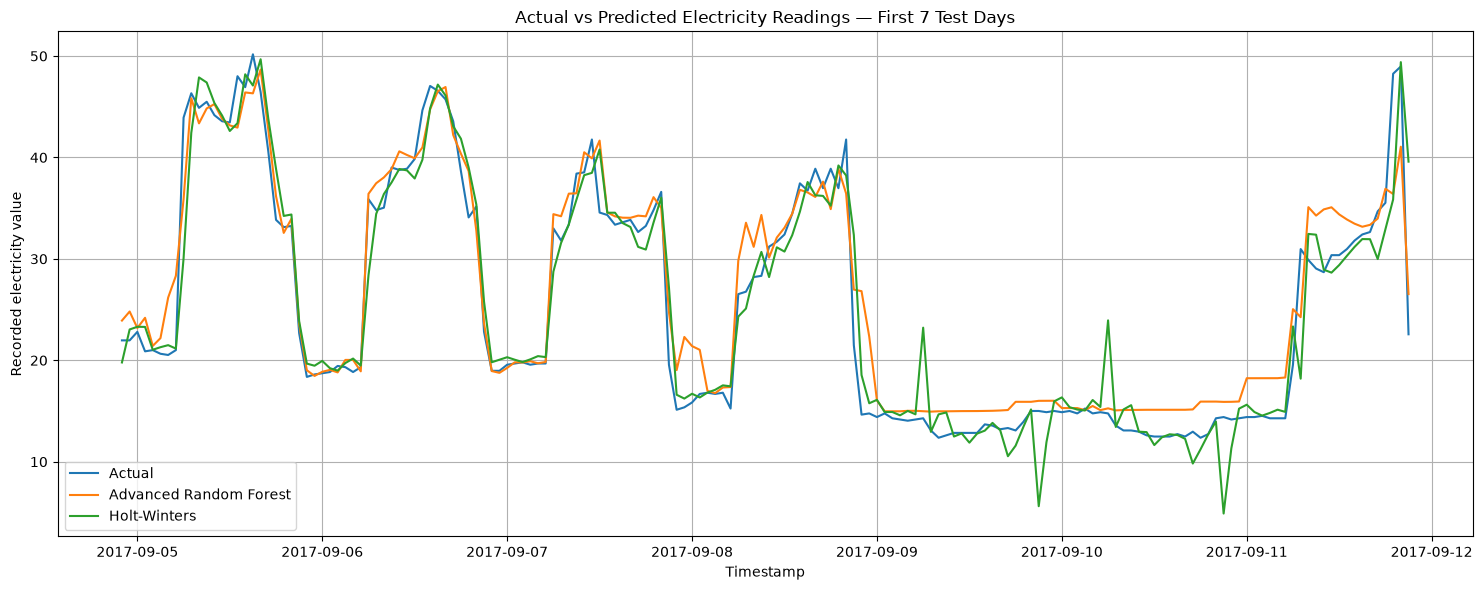

In [22]:
# Select first 7 days of the test period
plot_data = pd.DataFrame({
    "Actual": y_test_advanced,
    "Advanced Random Forest": rf_advanced_predictions,
    "Holt-Winters": hw_predictions
}).iloc[:168]

plt.figure(figsize=(15, 6))

plt.plot(plot_data.index, plot_data["Actual"], label="Actual")
plt.plot(plot_data.index, plot_data["Advanced Random Forest"], label="Advanced Random Forest")
plt.plot(plot_data.index, plot_data["Holt-Winters"], label="Holt-Winters")

plt.title("Actual vs Predicted Electricity Readings — First 7 Test Days")
plt.xlabel("Timestamp")
plt.ylabel("Recorded electricity value")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

1. Both models capture daily patterns

Both Random Forest and Holt-Winters follow the major rises and falls in actual electricity readings.

This suggests that the building has relatively consistent daily consumption patterns.

2. Advanced Random Forest follows sudden changes

The Random Forest generally responds well to sharp increases and decreases, although some predictions lag behind the actual changes.

3. Low-consumption period

Around September 9–11, consumption remains relatively low. Both models capture this transition, although their predictions are sometimes smoother than the actual readings.

4. Unexpected spikes

Holt-Winters has a few unusual deviations around September 10. The Random Forest also misses some sudden changes.

Research observation: Both models capture broad consumption patterns, but neither consistently predicts abrupt changes.

# Prediction error analysis

In [23]:
# Calculate prediction errors
error_analysis = pd.DataFrame(index=y_test_advanced.index)

error_analysis["Actual"] = y_test_advanced
error_analysis["Predicted"] = rf_advanced_predictions

error_analysis["Error"] = (
    error_analysis["Actual"] - error_analysis["Predicted"]
)

error_analysis["Absolute_Error"] = error_analysis["Error"].abs()

# Display the 10 largest prediction errors
largest_errors = error_analysis.sort_values(
    by="Absolute_Error",
    ascending=False
).head(10)

display(largest_errors.round(3))

,Actual,Predicted,Error,Absolute_Error
timestamp,,,,
2017-12-11 21:00:00,31.326,80.281,-48.955,48.955
2017-12-13 21:00:00,31.086,76.575,-45.489,45.489
2017-12-01 06:00:00,73.934,33.037,40.897,40.897
2017-11-16 06:00:00,74.774,36.219,38.556,38.556
2017-12-12 06:00:00,72.254,36.863,35.391,35.391
2017-12-11 06:00:00,71.174,35.896,35.278,35.278
2017-12-11 07:00:00,91.698,62.628,29.070,29.070
2017-12-14 06:00:00,69.013,42.185,26.828,26.828
2017-12-12 21:00:00,30.006,55.192,-25.186,25.186


In [24]:
# Combine prediction errors with the model's input features
error_diagnostics = error_analysis.join(X_test_advanced)

# Display the largest errors with their input features
display(
    error_diagnostics
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
    .round(3)
)

,Actual,Predicted,Error,Absolute_Error,lag_1,lag_2,lag_3,lag_24,lag_48,hour,day_of_week,is_weekend,rolling_mean_3,rolling_mean_24
timestamp,,,,,,,,,,,,,,
2017-12-11 21:00:00,31.326,80.281,-48.955,48.955,82.936,72.974,64.332,16.443,16.443,21,0,0,73.414,56.471
2017-12-13 21:00:00,31.086,76.575,-45.489,45.489,81.136,71.414,68.773,30.006,31.326,21,2,0,73.774,54.456
2017-12-01 06:00:00,73.934,33.037,40.897,40.897,31.326,30.966,29.406,28.926,27.965,6,4,0,30.566,42.408
2017-11-16 06:00:00,74.774,36.219,38.556,38.556,35.407,33.966,34.327,31.086,28.205,6,3,0,34.567,45.429
2017-12-12 06:00:00,72.254,36.863,35.391,35.391,18.964,18.964,18.964,71.174,20.884,6,1,0,18.964,56.651
2017-12-11 06:00:00,71.174,35.896,35.278,35.278,21.124,19.084,21.004,20.884,16.083,6,0,0,20.404,17.128
2017-12-11 07:00:00,91.698,62.628,29.070,29.070,71.174,21.124,19.084,18.604,14.403,7,0,0,37.127,19.224
2017-12-14 06:00:00,69.013,42.185,26.828,26.828,24.005,25.085,27.245,67.093,72.254,6,3,0,25.445,55.081
2017-12-12 21:00:00,30.006,55.192,-25.186,25.186,65.293,63.132,62.412,31.326,16.443,21,1,0,63.612,53.465


In [25]:
# Calculate absolute error by hour of the day
error_analysis["hour"] = error_analysis.index.hour

hourly_error = error_analysis.groupby("hour").agg(
    MAE=("Absolute_Error", "mean"),
    Mean_Error=("Error", "mean"),
    Observations=("Error", "count")
).reset_index()

display(hourly_error.round(3))

,hour,MAE,Mean_Error,Observations
0,0,0.890,-0.595,118
1,1,0.871,-0.612,118
2,2,0.828,-0.532,118
3,3,0.829,-0.519,118
4,4,0.893,-0.635,118
5,5,0.994,-0.758,118
6,6,4.603,1.473,118
7,7,4.072,0.891,118
8,8,2.992,-1.188,118
9,9,2.445,0.122,118


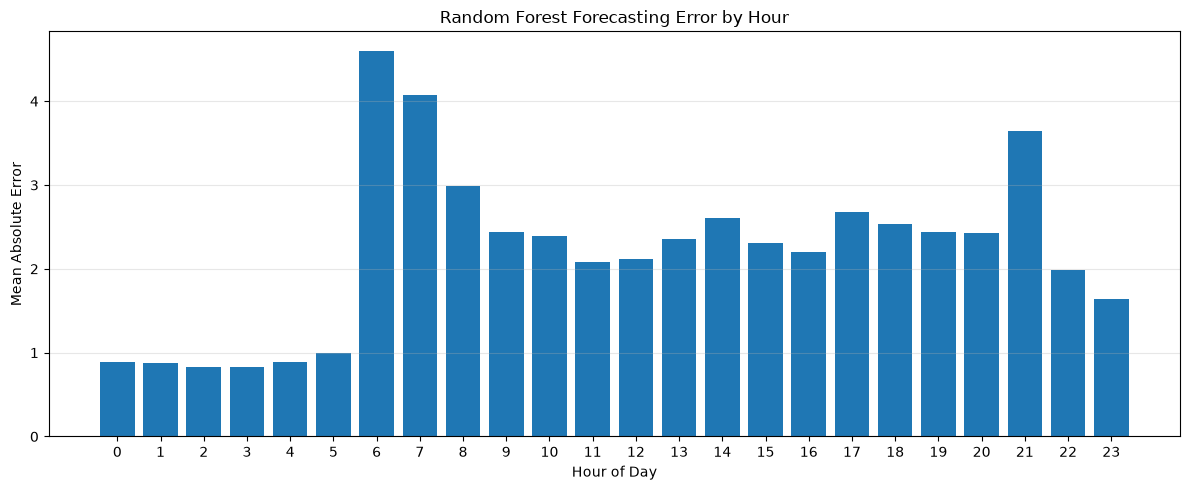

In [26]:
plt.figure(figsize=(12, 5))

plt.bar(
    hourly_error["hour"],
    hourly_error["MAE"]
)

plt.xlabel("Hour of Day")
plt.ylabel("Mean Absolute Error")
plt.title("Random Forest Forecasting Error by Hour")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [27]:
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    rf_advanced_model,
    X_test_advanced,
    y_test_advanced,
    n_repeats=5,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_test_advanced.columns,
    "Importance": permutation_result.importances_mean,
    "Std": permutation_result.importances_std
})

permutation_df = permutation_df.sort_values(
    "Importance",
    ascending=False
)

display(permutation_df.round(4))

,Feature,Importance,Std
0,lag_1,12.8904,0.1415
5,hour,0.9911,0.0229
6,day_of_week,0.8010,0.0222
3,lag_24,0.7256,0.0224
7,is_weekend,0.5465,0.0131
1,lag_2,0.2616,0.0061
9,rolling_mean_24,0.1936,0.0137
8,rolling_mean_3,0.1560,0.0030
2,lag_3,0.1176,0.0067
4,lag_48,0.1058,0.0062


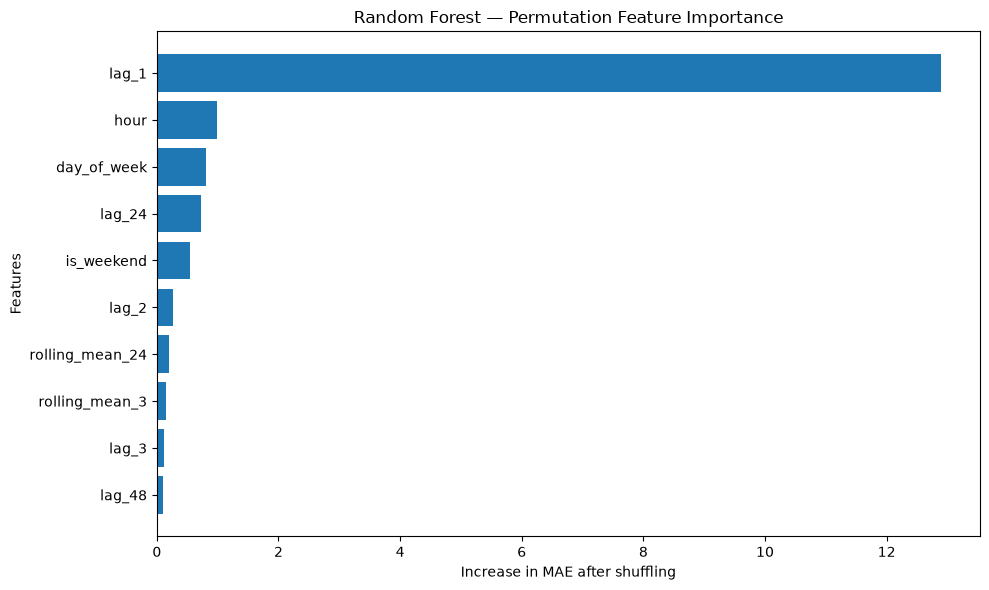

In [28]:
plt.figure(figsize=(10, 6))

plt.barh(
    permutation_df["Feature"],
    permutation_df["Importance"]
)

plt.xlabel("Increase in MAE after shuffling")
plt.ylabel("Features")
plt.title("Random Forest — Permutation Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [29]:
import joblib

# Save trained models
joblib.dump(
    rf_model,
    MODEL_DIR / "random_forest_baseline.pkl"
)

joblib.dump(
    rf_advanced_model,
    MODEL_DIR / "random_forest_advanced.pkl"
)

# Save predictions
ml_forecasts = pd.DataFrame({
    "actual": y_test_advanced,
    "baseline_rf": rf_predictions,
    "advanced_rf": rf_advanced_predictions
})

ml_forecasts.to_csv(
    FORECAST_DIR / "machine_learning_forecasts.csv"
)

# Save feature importance
feature_importance.to_csv(
    RESULT_DIR / "impurity_feature_importance.csv",
    index=False
)

permutation_df.to_csv(
    RESULT_DIR / "permutation_feature_importance.csv",
    index=False
)

# Save final model comparison
final_comparison.to_csv(
    RESULT_DIR / "final_model_comparison.csv",
    index=False
)

print("ML experiment saved successfully!")

ML experiment saved successfully!


In [30]:
# Verify saved experiment files
saved_files = [
    MODEL_DIR / "random_forest_baseline.pkl",
    MODEL_DIR / "random_forest_advanced.pkl",
    FORECAST_DIR / "machine_learning_forecasts.csv",
    RESULT_DIR / "impurity_feature_importance.csv",
    RESULT_DIR / "permutation_feature_importance.csv",
    RESULT_DIR / "final_model_comparison.csv"
]

for file_path in saved_files:
    status = "OK" if file_path.exists() else "MISSING"

    size = (
        f"{file_path.stat().st_size / 1024:.2f} KB"
        if file_path.exists()
        else "N/A"
    )

    print(f"{status:8} | {file_path.name:45} | {size}")

OK       | random_forest_baseline.pkl                    | 281878.89 KB
OK       | random_forest_advanced.pkl                    | 275619.47 KB
OK       | machine_learning_forecasts.csv                | 181.72 KB
OK       | impurity_feature_importance.csv               | 0.32 KB
OK       | permutation_feature_importance.csv            | 0.51 KB
OK       | final_model_comparison.csv                    | 0.33 KB


Main research findings

Finding 1 — Feature engineering improves forecasting

Adding time-based and rolling features reduced Random Forest MAE by approximately 21.3%.

Finding 2 — Previous-hour consumption dominates

lag_1 was the most important feature according to both impurity-based and permutation importance.

Finding 3 — Forecasting accuracy varies throughout the day

The model performed particularly well during night-time stable periods but struggled around 06:00–08:00 and 21:00.

Finding 4 — Historical readings have limitations

The model struggled to anticipate sudden consumption transitions. Weather, occupancy and HVAC schedules are potential additional sources of predictive information.

Important methodological limitations

Document these in your notebook:

1. The 11 original missing readings were interpolated for modelling; evaluation excluded those timestamps.

2. The Random Forest used rolling one-step-ahead features, with observed previous readings available during testing.

3. The Random Forest was trained once, not retrained during the test period.

4. SARIMA was evaluated over seven days only, so its results are not directly comparable with the full-test models.

5. Results represent one building meter, not a general conclusion about all buildings.

This study investigated statistical and machine-learning approaches for short-term electricity forecasting using the Building Data Genome Project 2 dataset. The Advanced Random Forest achieved the best performance, with an MAE of 2.200 and RMSE of 4.123 over the full test period. Feature engineering improved predictive accuracy compared with the baseline Random Forest. Feature importance analysis identified previous-hour electricity consumption as the dominant predictor, while temporal features provided additional information. Error analysis revealed reduced predictive accuracy during certain consumption transitions, particularly in the morning and evening. Future work could investigate weather, occupancy and building operational schedules to improve forecasting performance.